In [1]:
import pandas as pd
df = pd.read_csv('../data/clean_sales.csv', parse_dates=['InvoiceDate'])

In [2]:
df.shape

(1003404, 9)

In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [4]:
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).round(0)

Country
United Kingdom    16562935.0
EIRE                625038.0
Netherlands         549773.0
Germany             383419.0
France              311147.0
Name: Revenue, dtype: float64

In [5]:
df['month'] = df['InvoiceDate'].dt.month
df.groupby('month')['Revenue'].sum().round(0)


month
1     1214482.0
2     1045710.0
3     1451539.0
4     1161741.0
5     1383445.0
6     1434873.0
7     1321214.0
8     1398254.0
9     1897564.0
10    2197750.0
11    2881817.0
12    2019674.0
Name: Revenue, dtype: float64

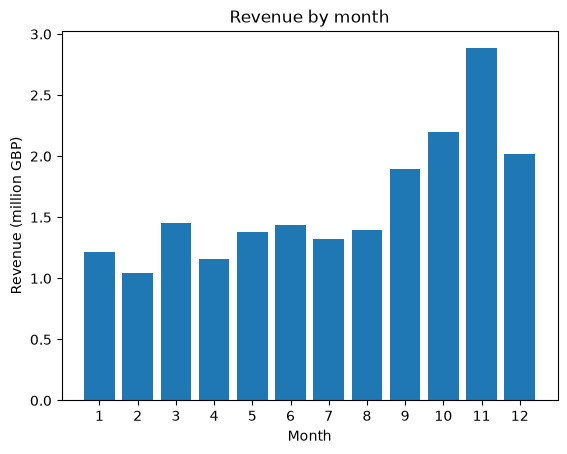

In [6]:
import matplotlib.pyplot as plt
df['month'] = df['InvoiceDate'].dt.month
monthly = df.groupby('month')['Revenue'].sum().round(0)
plt.bar(monthly.index, monthly.values / 1000000)
plt.title('Revenue by month')
plt.xlabel('Month')
plt.ylabel('Revenue (million GBP)')
plt.xticks(range(1, 13))
plt.savefig('../images/revenue_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

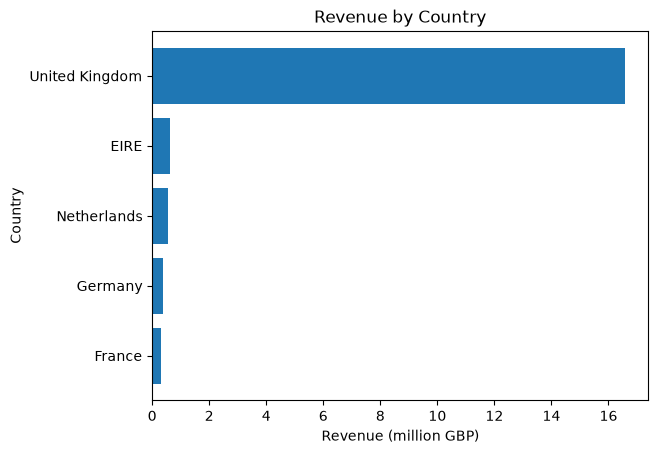

In [7]:
import matplotlib.pyplot as plt
countries = df.groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(countries.index, countries.values/1000000)
plt.title('Revenue by Country')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/revenue_by_country.png', dpi=150, bbox_inches='tight')
plt.show()


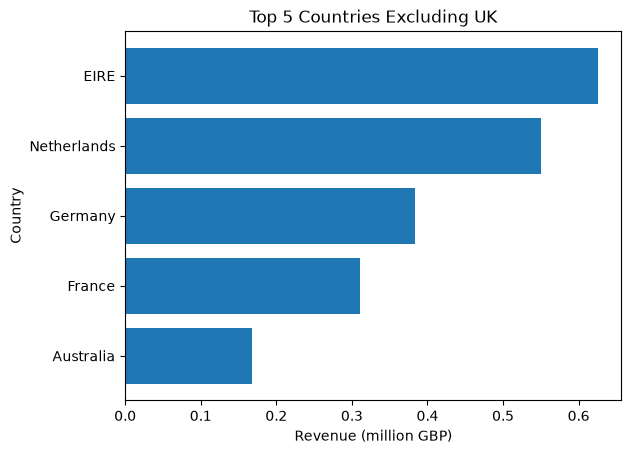

In [8]:
import matplotlib.pyplot as plt
#df = df[df['Country'] != 'United Kingdom']
df_intl = df[df['Country'] != 'United Kingdom'].groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(df_intl.index, df_intl.values/1000000)
plt.title('Top 5 Countries Excluding UK')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/top_international_countries.png', dpi=150, bbox_inches='tight')
plt.show()

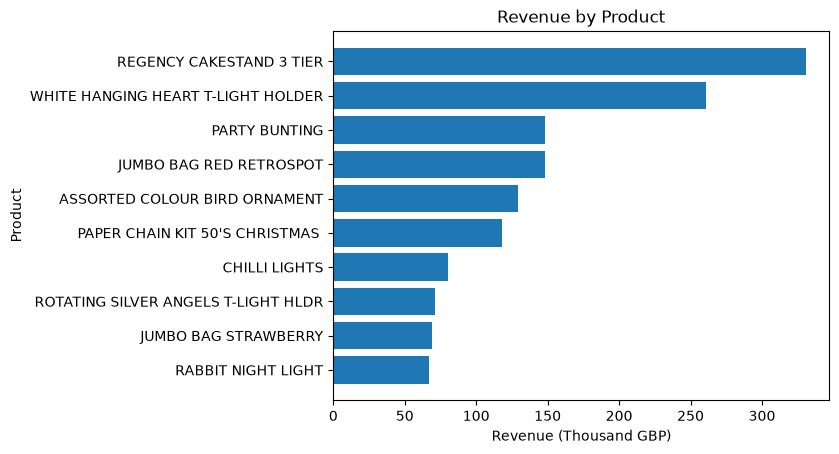

In [9]:
import matplotlib.pyplot as plt
not_products = df['Description'].isin(['Manual', 'DOTCOM POSTAGE', 'POSTAGE'])
df_products = df[~not_products]
products = df_products.groupby('Description')['Revenue'].sum().round(0).sort_values(ascending=False).head(10)
plt.barh(products.index, products.values/1000)
plt.title('Revenue by Product')
plt.xlabel('Revenue (Thousand GBP)')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.savefig('../images/revenue_by_product.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1003404 entries, 0 to 1003403
Data columns (total 10 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1003404 non-null  int64         
 1   StockCode    1003404 non-null  str           
 2   Description  1003404 non-null  str           
 3   Quantity     1003404 non-null  int64         
 4   InvoiceDate  1003404 non-null  datetime64[us]
 5   Price        1003404 non-null  float64       
 6   Customer ID  776639 non-null   float64       
 7   Country      1003404 non-null  str           
 8   Revenue      1003404 non-null  float64       
 9   month        1003404 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(1), int64(2), str(3)
memory usage: 72.7 MB


In [11]:
df['Customer ID'].nunique()

5861

In [12]:
df['Invoice'].nunique()

39563

In [13]:
df.shape

(1003404, 10)

In [14]:
df.sort_values('Quantity', ascending=False).head(3)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,month
86780,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.1,13902.0,Denmark,1915.2,2
121395,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,1296.0,3
121393,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,1296.0,3


In [15]:
df['StockCode'].str.len().value_counts()

StockCode
5    882043
6    119997
7      1223
8        99
9        25
4        17
Name: count, dtype: int64

In [16]:
df[df['StockCode'].str.len() < 5][['StockCode', 'Description']].drop_duplicates()

,StockCode,Description
59785,PADS,PADS TO MATCH ALL CUSHIONS
